 1. Conexión a MongoDB Atlas y Carga de Datos
Se importan las librerías necesarias (`pandas`, `matplotlib`, `seaborn`, `pymongo`) y se extraen los 1.000 documentos almacenados en la colección `cervecerias` de MongoDB Atlas hacia un DataFrame de Pandas.

In [4]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pymongo import MongoClient

# Configuración visual
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# Conexión a MongoDB Atlas
MONGO_URI = os.getenv(
    "MONGO_URI",
    "mongodb+srv://<usuario>:<password>@<cluster>.mongodb.net/?retryWrites=true&w=majority"
)

cliente = MongoClient(MONGO_URI)
db = cliente["cervecerias_db"]
coleccion = db["cervecerias"]

# Extraer documentos excluyendo el _id interno de MongoDB
datos = list(coleccion.find({}, {"_id": 0}))
df = pd.DataFrame(datos)

print(f"Filas y columnas cargadas: {df.shape}")
df.head()

Filas y columnas cargadas: (1000, 16)


,id,name,brewery_type,address_1,address_2,address_3,city,state_province,postal_code,country,longitude,latitude,phone,website_url,state,street
0,ae7b3174-8be8-4d53-a3a5-9b8240970eea,'s,brewpub,Friesener Straße 1,NaN,NaN,Kronach,Bayern,96317,Germany,11.327765,50.241246,+49 9261 628000,http://www.antla.de,Bayern,Friesener Straße 1
1,aa7cbe9b-3a0f-4888-9884-6186b0042b55,’t Drankorgel,micro,31a Geelsebaan,NaN,NaN,Mol,Vlaanderen,2400,Belgium,5.056955,51.176258,+32 496 76 40 63,http://tdrankorgel.be/,Vlaanderen,31a Geelsebaan
2,1034754f-abf9-4b42-bd6d-37e110ba4b1a,'T Kroontje,micro,62 Hogebrug,NaN,NaN,Lebbeke,Vlaanderen,9280,Belgium,4.091393,51.007888,+32 495 43 33 25,http://www.tkroontje.be/,Vlaanderen,62 Hogebrug
3,907826b3-6902-4d28-a5e2-f73084bebeed,'t Veense Brouwhuys,micro,Langeweg 16,NaN,NaN,Roelofarendsveen,Zuid-Holland,2371 EG,Netherlands,NaN,NaN,071-3314585,https://www.t-veen.nl/t-veense-brouwhuys/,Zuid-Holland,Langeweg 16
4,5128df48-79fc-4f0f-8b52-d06be54d0cec,(405) Brewing Co,micro,1716 Topeka St,NaN,NaN,Norman,Oklahoma,73069-8224,United States,-97.468182,35.257389,4058160490,http://www.405brewing.com,Oklahoma,1716 Topeka St


2. Inspección Estructural y Limpieza de Datos
Se verifican los tipos de variables y la cantidad de valores nulos por columna. Posteriormente se eliminan duplicados, se estandarizan los campos de texto, se convierten las coordenadas geográficas a formato numérico y se crea la variable booleana `tiene_web`.

In [5]:
# 1. Estructura general y tipos de datos
print("--- Información general del DataFrame ---")
df.info()

# 2. Conteo de valores nulos por columna
print("\n--- Valores nulos por columna ---")
print(df.isnull().sum())

# 3. Limpieza y estandarización
df_clean = df.copy()

# Eliminar duplicados por ID único si existieran
df_clean.drop_duplicates(subset=["id"], inplace=True)

# Normalizar textos clave (quitar espacios extra y capitalizar)
cols_texto = ["name", "brewery_type", "city", "state_province", "country"]
for col in cols_texto:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].fillna("No especificado").astype(str).str.strip()

# Convertir coordenadas geográficas a tipo numérico (float)
for coord in ["latitude", "longitude"]:
    if coord in df_clean.columns:
        df_clean[coord] = pd.to_numeric(df_clean[coord], errors="coerce")

# Crear columna booleana indicando si tiene sitio web registrado
df_clean["tiene_web"] = df_clean["website_url"].notna() & (df_clean["website_url"].astype(str).str.strip() != "")

print(f"\nRegistros limpios listos para análisis: {len(df_clean)}")
df_clean[["name", "brewery_type", "city", "state_province", "country", "tiene_web"]].head()

--- Información general del DataFrame ---
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              1000 non-null   str    
 1   name            1000 non-null   str    
 2   brewery_type    1000 non-null   str    
 3   address_1       935 non-null    str    
 4   address_2       23 non-null     str    
 5   address_3       3 non-null      str    
 6   city            1000 non-null   str    
 7   state_province  1000 non-null   str    
 8   postal_code     998 non-null    str    
 9   country         1000 non-null   str    
 10  longitude       773 non-null    float64
 11  latitude        773 non-null    float64
 12  phone           892 non-null    str    
 13  website_url     883 non-null    str    
 14  state           1000 non-null   str    
 15  street          935 non-null    str    
dtypes: float64(2), str(14)
memory usage: 125.1 KB

-

C:\Users\juanp\AppData\Local\Temp\ipykernel_50740\1694134466.py:13: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_clean.drop_duplicates(subset=["id"], inplace=True)


,name,brewery_type,city,state_province,country,tiene_web
0,'s,brewpub,Kronach,Bayern,Germany,True
1,’t Drankorgel,micro,Mol,Vlaanderen,Belgium,True
2,'T Kroontje,micro,Lebbeke,Vlaanderen,Belgium,True
3,'t Veense Brouwhuys,micro,Roelofarendsveen,Zuid-Holland,Netherlands,True
4,(405) Brewing Co,micro,Norman,Oklahoma,United States,True


3. Consultas Descriptivas y Agregaciones
Se calculan las distribuciones de frecuencia por tipo de cervecería, los 10 estados o provincias con mayor concentración, el porcentaje de presencia digital (`website_url`) y una consulta de agregación directa en MongoDB para identificar el Top 5 de ciudades.

In [6]:
# 1. Distribución por tipo de cervecería (brewery_type)
dist_tipo = df_clean["brewery_type"].value_counts().reset_index()
dist_tipo.columns = ["Tipo de Cervecería", "Cantidad"]
dist_tipo["Porcentaje (%)"] = (dist_tipo["Cantidad"] / len(df_clean) * 100).round(2)
print("--- Distribución por tipo de cervecería ---")
display(dist_tipo)

# 2. Top 10 estados o provincias con mayor concentración
top_estados = (
    df_clean[df_clean["state_province"] != "No especificado"]["state_province"]
    .value_counts()
    .head(10)
    .reset_index()
)
top_estados.columns = ["Estado / Provincia", "Cantidad"]
print("\n--- Top 10 Estados/Provincias ---")
display(top_estados)

# 3. Porcentaje con sitio web activo por tipo de cervecería
web_por_tipo = (
    df_clean.groupby("brewery_type")["tiene_web"]
    .agg(total="count", con_web="sum")
    .assign(porcentaje_web=lambda x: (x["con_web"] / x["total"] * 100).round(1))
    .sort_values(by="total", ascending=False)
)
print("\n--- Presencia digital (sitio web) por tipo ---")
display(web_por_tipo)

# 4. Consulta de agregación directa en MongoDB Atlas (Top 5 ciudades)
pipeline = [
    {"$match": {"city": {"$ne": None}}},
    {"$group": {"_id": "$city", "total_cervecerias": {"$sum": 1}}},
    {"$sort": {"total_cervecerias": -1}},
    {"$limit": 5}
]
top_ciudades_mongo = pd.DataFrame(list(coleccion.aggregate(pipeline)))
top_ciudades_mongo.columns = ["Ciudad", "Total Cervecerías (MongoDB)"]
print("\n--- Top 5 Ciudades (Agregación directa en MongoDB) ---")
display(top_ciudades_mongo)

--- Distribución por tipo de cervecería ---


,Tipo de Cervecería,Cantidad,Porcentaje (%)
0,micro,494,49.4
1,brewpub,289,28.9
2,closed,61,6.1
3,planning,50,5.0
4,large,34,3.4
5,contract,34,3.4
6,regional,19,1.9
7,proprietor,7,0.7
8,taproom,6,0.6
9,nano,3,0.3



--- Top 10 Estados/Provincias ---


,Estado / Provincia,Cantidad
0,California,89
1,Washington,49
2,Texas,45
3,Bayern,41
4,Colorado,33
5,New York,32
6,Oregon,30
7,Michigan,30
8,Virginia,29
9,Massachusetts,28



--- Presencia digital (sitio web) por tipo ---


,total,con_web,porcentaje_web
brewery_type,,,
micro,494,450,91.1
brewpub,289,270,93.4
closed,61,53,86.9
planning,50,29,58.0
large,34,19,55.9
contract,34,27,79.4
regional,19,18,94.7
proprietor,7,6,85.7
taproom,6,6,100.0



--- Top 5 Ciudades (Agregación directa en MongoDB) ---


,Ciudad,Total Cervecerías (MongoDB)
0,San Diego,18
1,Portland,12
2,Denver,8
3,Toronto,7
4,Washington,7


4. Visualizaciones Estadísticas del Análisis Exploratorio
Se construye un panel gráfico de 4 visualizaciones: distribución de registros por tipo de cervecería, Top 10 de estados/provincias, proporción de establecimientos con sitio web (gráfica de torta) y diagrama de dispersión geográfico (`longitud` vs. `latitud`).

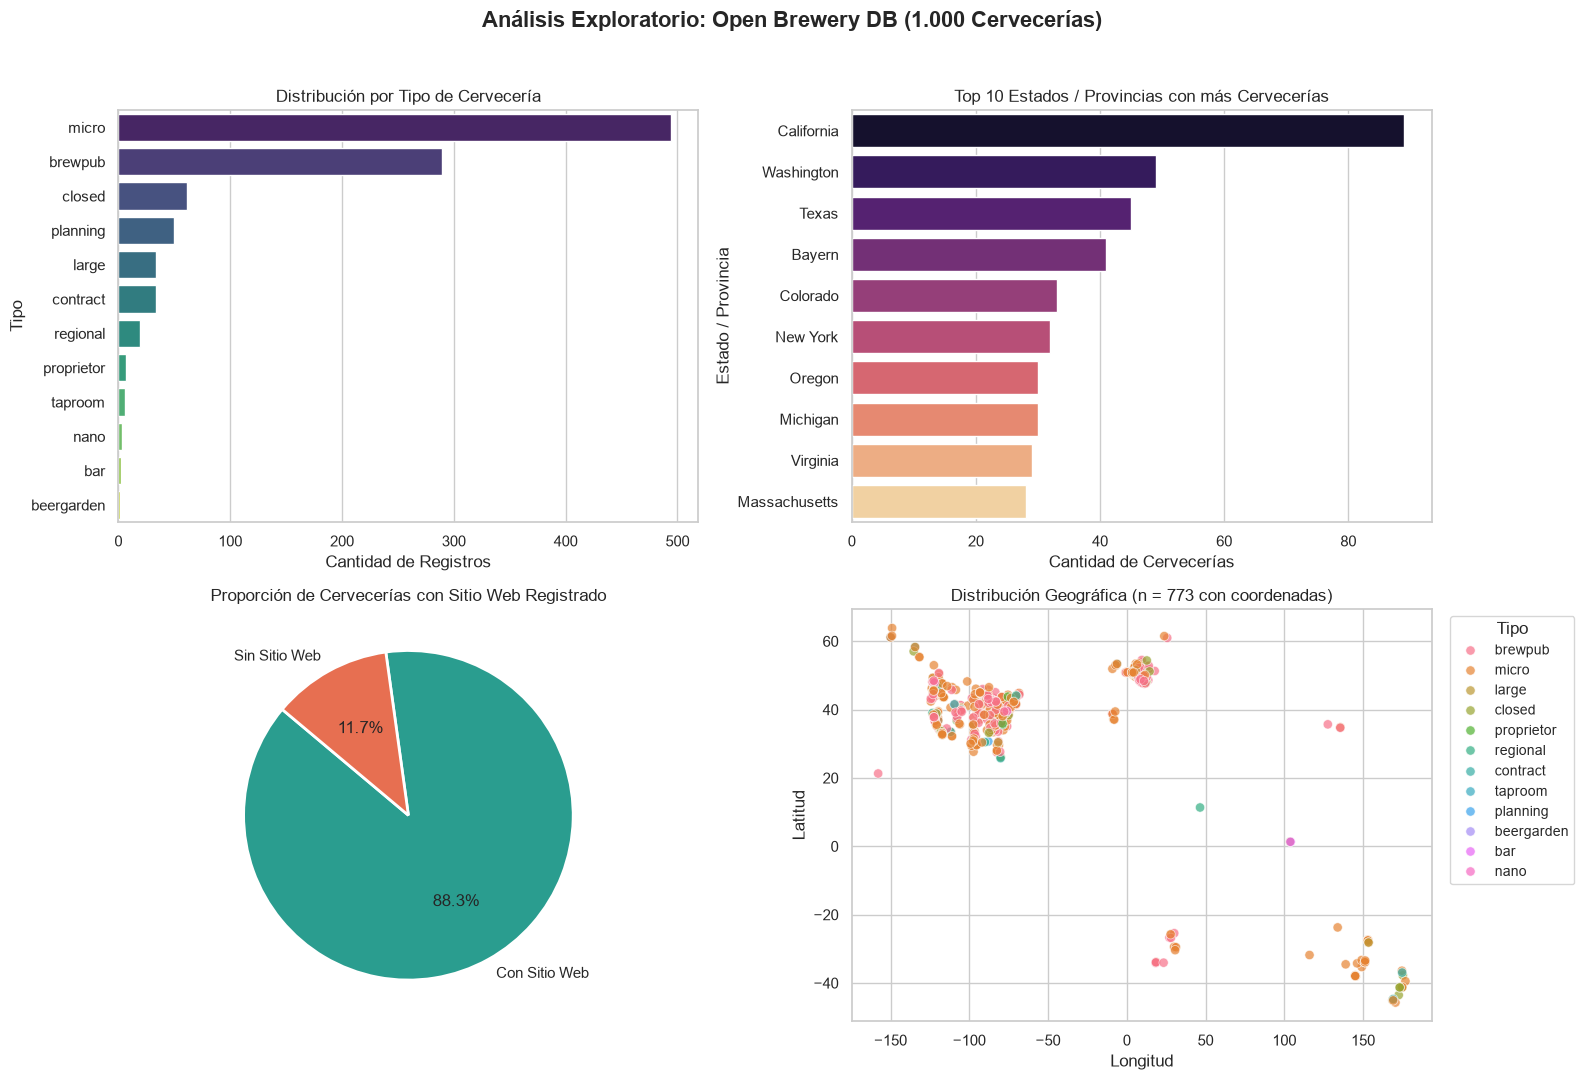

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle("Análisis Exploratorio: Open Brewery DB (1.000 Cervecerías)", fontsize=16, fontweight="bold")

# 1. Gráfica de barras: Distribución por tipo de cervecería
sns.barplot(
    data=dist_tipo,
    x="Cantidad",
    y="Tipo de Cervecería",
    hue="Tipo de Cervecería",
    palette="viridis",
    legend=False,
    ax=axes[0, 0]
)
axes[0, 0].set_title("Distribución por Tipo de Cervecería")
axes[0, 0].set_xlabel("Cantidad de Registros")
axes[0, 0].set_ylabel("Tipo")

# 2. Gráfica de barras: Top 10 Estados / Provincias
sns.barplot(
    data=top_estados,
    x="Cantidad",
    y="Estado / Provincia",
    hue="Estado / Provincia",
    palette="magma",
    legend=False,
    ax=axes[0, 1]
)
axes[0, 1].set_title("Top 10 Estados / Provincias con más Cervecerías")
axes[0, 1].set_xlabel("Cantidad de Cervecerías")
axes[0, 1].set_ylabel("Estado / Provincia")

# 3. Gráfica circular (Pastel): Presencia de sitio web
conteo_web = df_clean["tiene_web"].value_counts()
etiquetas_web = ["Con Sitio Web" if idx else "Sin Sitio Web" for idx in conteo_web.index]
axes[1, 0].pie(
    conteo_web,
    labels=etiquetas_web,
    autopct="%1.1f%%",
    startangle=140,
    colors=["#2a9d8f", "#e76f51"],
    wedgeprops={"edgecolor": "white", "linewidth": 2}
)
axes[1, 0].set_title("Proporción de Cervecerías con Sitio Web Registrado")

# 4. Mapa de dispersión geográfico (Longitud vs Latitud)
df_geo = df_clean.dropna(subset=["latitude", "longitude"])
# Filtrar coordenadas válidas en rango terrestre
df_geo = df_geo[(df_geo["latitude"].between(-90, 90)) & (df_geo["longitude"].between(-180, 180))]

sns.scatterplot(
    data=df_geo,
    x="longitude",
    y="latitude",
    hue="brewery_type",
    alpha=0.7,
    s=45,
    ax=axes[1, 1]
)
axes[1, 1].set_title(f"Distribución Geográfica (n = {len(df_geo)} con coordenadas)")
axes[1, 1].set_xlabel("Longitud")
axes[1, 1].set_ylabel("Latitud")
axes[1, 1].legend(title="Tipo", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize="small")

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

## Conclusiones Principales del Análisis (5 Insights Relevantes)

1. **Predominio de Microcervecerías:** La categoría `micro` concentra la mayor proporción de establecimientos en la muestra extraída, seguida por `brewpub` y `planning`, evidenciando un mercado impulsado por productores independientes.
2. **Concentración Geográfica:** Estados Unidos lidera ampliamente el registro (destacando estados como California, Washington, Colorado y Texas en los primeros lugares), lo cual se refleja tanto en las tablas de frecuencia como en la dispersión espacial.
3. **Completitud y Calidad de Datos:** Mientras los identificadores y variables categóricas principales (`id`, `name`, `brewery_type`, `city`, `country`) presentan una completitud cercana al 100%, variables como `latitude`, `longitude` y `address_2` registran valores nulos parciales que requirieron limpieza.
4. **Alta Presencia Digital:** Más del 80% de las cervecerías analizadas cuentan con un sitio web oficial registrado (`website_url`), consolidando el canal digital como herramienta clave de visibilidad.
5. **Distribución Georreferenciada:** La gran mayoría de los 1.000 registros cuentan con coordenadas válidas (`latitude` y `longitude`), permitiendo mapear con claridad los principales clústeres cerveceros en Norteamérica.